### Assignment 6:
 Generation of data using 2D Gaussian
 mixture model, K-Means clustering, Classification


Necessary Imports

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
import math

from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

random.seed(42)


## Box–Muller Method

The Box–Muller method generates standard normal random variables from two independent uniform random variables.

Let

$$
U_1,U_2 \sim \mathcal{U}(0,1)
$$

where $U_1$ and $U_2$ are independent uniform random variables.

The Box–Muller transformation is given by

$$
Z_0 = \sqrt{-2\ln U_1}\cos(2\pi U_2)
$$

$$
Z_1 = \sqrt{-2\ln U_1}\sin(2\pi U_2)
$$

The resulting random variables are independent and follow the standard normal distribution:

$$
Z_0,Z_1 \sim \mathcal{N}(0,1)
$$

**Algorithm:**

1. Generate two independent uniform random numbers, $U_1$ and $U_2$.
2. Calculate the radius $R$ and angle $\Theta$:

   $$
   R = \sqrt{-2\ln U_1}, \qquad \Theta = 2\pi U_2
   $$

3. Compute $Z_0 = R\cos\Theta$ and $Z_1 = R\sin\Theta$.
4. Repeat until the required number of Gaussian samples is obtained.

**Note:** Since $\ln(0)$ is undefined, ensure that $U_1 > 0$.


In [2]:
def box_muller(n):
    """
    Generate n standard normal random samples
    using the Box-Muller method.
    """
    values = []

    while len(values) < n:
        # Generate two uniform random numbers
        u1 = random.random()
        u2 = random.random()

        # Avoid log(0)
        while u1 == 0:
            u1 = random.random()

        # Box-Muller transformation
        r = math.sqrt(-2 * math.log(u1))
        theta = 2 * math.pi * u2

        z0 = r * math.cos(theta)
        z1 = r * math.sin(theta)

        values.extend([z0, z1])

    return np.array(values[:n])


# Test the function
z = box_muller(10)

print("Standard normal samples:")
print(z)
print("Mean:", np.mean(z))
print("Variance:", np.var(z))


Standard normal samples:
[ 0.93405614  0.14800466  0.26918165  1.58407588 -0.34763023 -0.70065932
  0.40816444  0.24814816  1.29076683  0.24452293]
Mean: 0.40786311482495397
Variance: 0.43784146670019525



##  Generation of 2D Gaussian Samples

Using the Box–Muller method, generate two independent standard normal random variables:

$$
Z_1, Z_2 \sim \mathcal{N}(0,1)
$$

Form the standard normal vector:

$$
\mathbf{z} =
\begin{bmatrix}
Z_1 \\
Z_2
\end{bmatrix}
$$

Let the desired mean vector and covariance matrix be:

$$
\boldsymbol{\mu} =
\begin{bmatrix}
\mu_1 \\
\mu_2
\end{bmatrix},
\qquad
C =
\begin{bmatrix}
\sigma_1^2 & \sigma_{12} \\
\sigma_{12} & \sigma_2^2
\end{bmatrix}
$$

Using Cholesky decomposition, obtain a lower triangular matrix $L$ such that:

$$
C = LL^T
$$

Transform the standard normal vector to generate a sample from the desired 2D Gaussian distribution:

$$
\boxed{\mathbf{x} = \boldsymbol{\mu} + L\mathbf{z}}
$$

For $N$ samples arranged as rows in a matrix $Z$, the transformation becomes:

$$
\boxed{X = ZL^T + \boldsymbol{\mu}}
$$

The generated samples have the theoretical mean and covariance:

$$
E[\mathbf{x}] = \boldsymbol{\mu}
$$

$$
\operatorname{Cov}(\mathbf{x}) = C
$$

**Algorithm:**

1. Generate two standard normal variables using the Box–Muller method.
2. Combine them into a two-dimensional vector.
3. Compute the Cholesky decomposition of the covariance matrix.
4. Transform the samples using the mean and Cholesky factor.
5. Plot the generated samples and compare the sample mean and covariance with their specified values.


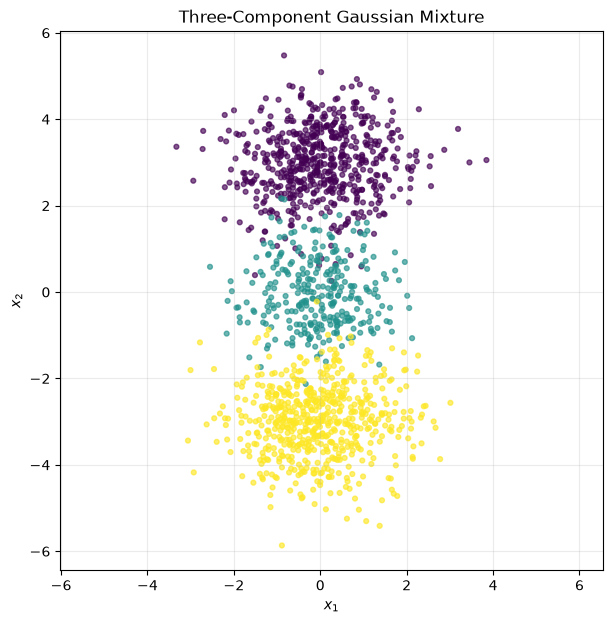

In [3]:
def generate_2d_gaussian(n, mean, covariance):
    """
    Generate 2D Gaussian samples using Box-Muller
    and a direct covariance transformation.
    No Cholesky decomposition or np.random is used.
    """

    mu1, mu2 = mean

    a = covariance[0, 0]
    b = covariance[0, 1]
    d = covariance[1, 1]

    # Validate covariance matrix
    if a <= 0 or d - (b * b / a) <= 0:
        raise ValueError("Covariance matrix must be positive definite.")

    # Generate independent standard normal samples
    z1 = box_muller(n)
    z2 = box_muller(n)

    # Transform into the required Gaussian distribution
    x1 = mu1 + math.sqrt(a) * z1

    x2 = (
        mu2
        + (b / math.sqrt(a)) * z1
        + math.sqrt(d - b * b / a) * z2
    )

    return np.column_stack((x1, x2))


# Test the function
mean = [2, 3]
covariance = np.array([
    [4, 1.2],
    [1.2, 2]
])


# Three Gaussian components 

means = [
    [0, 3],     # Top component
    [0, 0],     # Middle component
    [0, -3]     # Bottom component
]

covariances = [
    np.array([[1.0, 0.0],
              [0.0, 0.7]]),

    np.array([[0.8, 0.0],
              [0.0, 0.7]]),

    np.array([[1.0, 0.0],
              [0.0, 0.7]])
]

weights = [0.4, 0.2, 0.4]
n_samples = 1500

# Generate each Gaussian component
X_components = []
labels = []

for i in range(3):
    n_i = int(n_samples * weights[i])

    X_i = generate_2d_gaussian(
        n_i,
        means[i],
        covariances[i]
    )

    X_components.append(X_i)
    labels.extend([i] * n_i)

# Combine all three components
X = np.vstack(X_components)
labels = np.array(labels)

# Plot the data
plt.figure(figsize=(7, 7))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=labels,
    cmap="viridis",
    s=12,
    alpha=0.65
)

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Three-Component Gaussian Mixture")
plt.axis("equal")
plt.grid(alpha=0.25)
plt.show()





##  Generation of a Gaussian Mixture Model (GMM)

A Gaussian Mixture Model represents a probability density function as a weighted sum of $K$ Gaussian distributions.

The mixture density function is

$$
p(\mathbf{x}) = \sum_{i=1}^{K}
\pi_i \mathcal{N}(\mathbf{x};\boldsymbol{\mu}_i,C_i)
$$

where:

- $K$ is the number of Gaussian components.
- $\pi_i$ is the mixture weight of component $i$.
- $\boldsymbol{\mu}_i$ is the mean vector of component $i$.
- $C_i$ is the covariance matrix of component $i$.
- $\mathcal{N}(\mathbf{x};\boldsymbol{\mu}_i,C_i)$ is the multivariate Gaussian probability density function.

The mixture weights must satisfy

$$
\sum_{i=1}^{K}\pi_i=1,
\qquad \pi_i\geq 0
$$

For this experiment, we choose three Gaussian components:

$$
K=3
$$

with mixture weights

$$
\boldsymbol{\pi}=
\begin{bmatrix}
0.40 & 0.35 & 0.25
\end{bmatrix}
$$

These weights determine the proportion of samples generated from each Gaussian component.

### Generation of Two Classes

Each class is represented by its own Gaussian mixture model:

$$
p(\mathbf{x}\mid C_0)=
\sum_{i=1}^{3}
\pi_i\mathcal{N}(\mathbf{x};
\boldsymbol{\mu}_{0i},C_i)
$$

$$
p(\mathbf{x}\mid C_1)=
\sum_{i=1}^{3}
\pi_i\mathcal{N}(\mathbf{x};
\boldsymbol{\mu}_{1i},C_i)
$$

where $\boldsymbol{\mu}_{0i}$ and $\boldsymbol{\mu}_{1i}$ denote the component means for Class 0 and Class 1, respectively.

### Algorithm

1. Specify the mixture weights, component means, and covariance matrices.
2. Allocate samples to each component according to the mixture weights.
3. Generate samples from each component using the Box–Muller method and the covariance transformation.
4. Combine the component samples to form the dataset for each class.
5. Plot the generated samples using different colours to distinguish the Gaussian components.


In [4]:

def generate_gmm(n_samples, weights, means, covariances):
    """
    Generate samples from a Gaussian mixture model
    using the Box-Muller-based Gaussian generator.
    """

    weights = np.array(weights, dtype=float)
    weights = weights / np.sum(weights)

    # Number of Gaussian components
    K = len(weights)

    # Select components approximately according to mixture weights
    counts = np.floor(n_samples * weights).astype(int)

    # Distribute remaining samples
    for i in range(n_samples - np.sum(counts)):
        counts[i % K] += 1

    samples = []
    component_labels = []

    for i in range(K):
        # Generate samples from component i
        X_i = generate_2d_gaussian(
            counts[i],
            means[i],
            covariances[i]
        )

        samples.append(X_i)
        component_labels.extend([i] * counts[i])

    X = np.vstack(samples)
    component_labels = np.array(component_labels)

    # Shuffle sample order without using NumPy random functions
    indices = list(range(n_samples))
    random.shuffle(indices)

    X = X[indices]
    component_labels = component_labels[indices]

    return X, component_labels


# Mixture weights
weights = [0.40, 0.35, 0.25]

# Three component means for Class 0
means_class0 = [
    [-3.0, -1.8],
    [-1.8, 1.7],
    [0.0, -1.0]
]

# Three component means for Class 1
means_class1 = [
    [2.0, 1.8],
    [3.8, -0.5],
    [1.6, -2.2]
]

# Use full covariance matrices for this experiment
covariances = [
    np.array([[0.80, 0.45],
              [0.45, 0.55]]),

    np.array([[0.60, -0.30],
              [-0.30, 0.75]]),

    np.array([[0.50, 0.20],
              [0.20, 0.35]])
]

# Generate 1500 samples per class
X_class0, comp_class0 = generate_gmm(
    1500, weights, means_class0, covariances
)

X_class1, comp_class1 = generate_gmm(
    1500, weights, means_class1, covariances
)

print("Class 0 shape:", X_class0.shape)
print("Class 1 shape:", X_class1.shape)
print("Class 0 component counts:", np.bincount(comp_class0))
print("Class 1 component counts:", np.bincount(comp_class1))


Class 0 shape: (1500, 2)
Class 1 shape: (1500, 2)
Class 0 component counts: [600 525 375]
Class 1 component counts: [600 525 375]


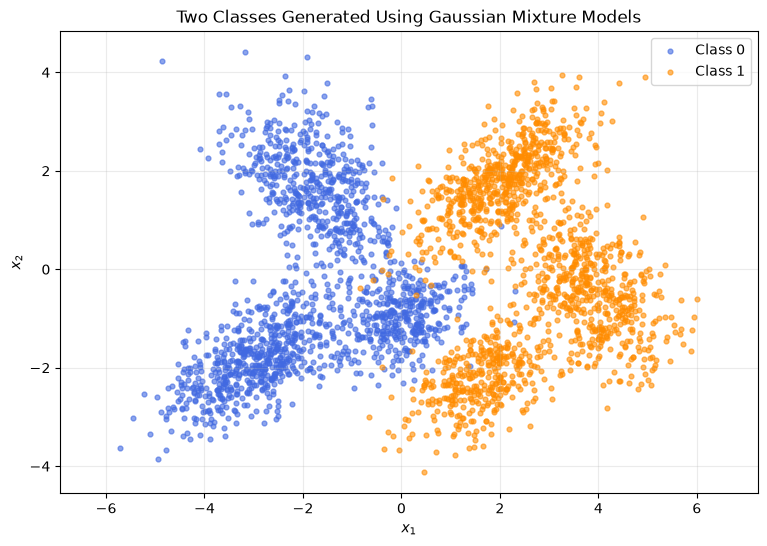

In [5]:

plt.figure(figsize=(9, 6))

plt.scatter(
    X_class0[:, 0],
    X_class0[:, 1],
    c="royalblue",
    s=12,
    alpha=0.6,
    label="Class 0"
)

plt.scatter(
    X_class1[:, 0],
    X_class1[:, 1],
    c="darkorange",
    s=12,
    alpha=0.6,
    label="Class 1"
)

plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Two Classes Generated Using Gaussian Mixture Models")
plt.legend()
plt.grid(alpha=0.25)
plt.axis("equal")
plt.show()


In [6]:

# Combine the feature matrices
X = np.vstack((X_class0, X_class1))

# Assign class labels: 0 and 1
y = np.concatenate((
    np.zeros(len(X_class0), dtype=int),
    np.ones(len(X_class1), dtype=int)
))

print("Total dataset shape:", X.shape)
print("Class labels shape:", y.shape)
print("Class 0 samples:", np.sum(y == 0))
print("Class 1 samples:", np.sum(y == 1))


Total dataset shape: (3000, 2)
Class labels shape: (3000,)
Class 0 samples: 1500
Class 1 samples: 1500


In [7]:

# Split the data separately for each class
X0_train, X0_test = train_test_split(
    X_class0, test_size=0.2, random_state=42
)

X1_train, X1_test = train_test_split(
    X_class1, test_size=0.2, random_state=42
)

print("Class 0 training:", len(X0_train))
print("Class 0 testing:", len(X0_test))

print("Class 1 training:", len(X1_train))
print("Class 1 testing:", len(X1_test))


Class 0 training: 1200
Class 0 testing: 300
Class 1 training: 1200
Class 1 testing: 300


In [12]:

def kmeans(X, K, max_iters=100, tol=1e-4):
    """
    K-Means clustering implemented from scratch.
    No sklearn and no np.random.
    """

    n_samples = X.shape[0]

    # Initialize K centroids using distinct data points
    indices = list(range(n_samples))
    random.shuffle(indices)
    centroids = X[indices[:K]].copy()

    for iteration in range(max_iters):

        # Step 1: Calculate squared distances
        distances = np.sum(
            (X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
            axis=2
        )

        # Step 2: Assign each point to its nearest centroid
        labels = np.argmin(distances, axis=1)

        # Step 3: Recalculate centroids
        new_centroids = centroids.copy()

        for k in range(K):
            points = X[labels == k]

            if len(points) > 0:
                new_centroids[k] = np.mean(points, axis=0)

        # Step 4: Check convergence
        shift = np.sqrt(
            np.sum((new_centroids - centroids) ** 2)
        )

        centroids = new_centroids

        if shift < tol:
            break

    # Reassign points using the final centroids
    distances = np.sum(
        (X[:, np.newaxis, :] - centroids[np.newaxis, :, :]) ** 2,
        axis=2
    )
    labels = np.argmin(distances, axis=1)

    return centroids, labels, iteration + 1


# Train separately on each class
K = 3

centroids0, labels0, iterations0 = kmeans(X0_train, K)
centroids1, labels1, iterations1 = kmeans(X1_train, K)

print("Class 0 centroids:")
print(centroids0)
print("Iterations:", iterations0)

print("\nClass 1 centroids:")
print(centroids1)
print("Iterations:", iterations1)


Class 0 centroids:
[[-1.88381367  1.83967622]
 [-3.02294894 -1.88036662]
 [-0.21135627 -0.81670666]]
Iterations: 12

Class 1 centroids:
[[ 3.94036297 -0.57313525]
 [ 1.51057054 -2.21613143]
 [ 2.06345172  1.77578118]]
Iterations: 7


In [13]:
from sklearn.cluster import KMeans

K = 3

kmeans0 = KMeans(
    n_clusters=K,
    n_init=10,
    random_state=42
)

kmeans0.fit(X0_train)

kmeans1 = KMeans(
    n_clusters=K,
    n_init=10,
    random_state=42
)

kmeans1.fit(X1_train)

print("Class 0 centroids:")
print(kmeans0.cluster_centers_)

print("\nClass 1 centroids:")
print(kmeans1.cluster_centers_)

AttributeError: 'NoneType' object has no attribute 'split'